In [1]:
import pandas as pd
import numpy as np


files = [r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_A.csv",
         r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_B.csv",
         r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_D.csv",
         r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_H.csv",
         r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_L.csv",
         r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_P.csv",
         r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_R.csv",
         r"C:\Users\Ahmed\Downloads\Project_DEPI\Code\ddinter_downloads_code_V.csv"]
dfs = [pd.read_csv(file) for file in files]
df = pd.concat(dfs,ignore_index = True)

In [2]:
print(f'The shape \n {df.shape}')
print(f'The size \n {df.size}')
print(f'The columns \n {df.columns}')
print('\n\n\nSample of Dataaaaaaaaaaa')
print(df.head())

The shape 
 (222383, 5)
The size 
 1111915
The columns 
 Index(['DDInterID_A', 'Drug_A', 'DDInterID_B', 'Drug_B', 'Level'], dtype='str')



Sample of Dataaaaaaaaaaa
   DDInterID_A              Drug_A  DDInterID_B        Drug_B     Level
0  DDInter1263          Naltrexone     DDInter1      Abacavir  Moderate
1     DDInter1            Abacavir  DDInter1348      Orlistat  Moderate
2    DDInter58  Aluminum hydroxide   DDInter582  Dolutegravir     Major
3   DDInter112          Aprepitant   DDInter582  Dolutegravir     Minor
4   DDInter138         Attapulgite   DDInter582  Dolutegravir     Major


In [3]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 222383 entries, 0 to 222382
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   DDInterID_A  222383 non-null  str  
 1   Drug_A       222383 non-null  str  
 2   DDInterID_B  222383 non-null  str  
 3   Drug_B       222383 non-null  str  
 4   Level        222383 non-null  str  
dtypes: str(5)
memory usage: 19.7 MB


DDInterID_A    0
Drug_A         0
DDInterID_B    0
Drug_B         0
Level          0
dtype: int64

In [4]:
print(f'The number of duplication {df.duplicated().sum()}')
print(df[df.duplicated()])
print(df.drop_duplicates().shape)

The number of duplication 62148
        DDInterID_A                Drug_A  DDInterID_B              Drug_B  \
56367    DDInter975                  Iron   DDInter582        Dolutegravir   
56370    DDInter582          Dolutegravir  DDInter1114  Magnesium chloride   
56371    DDInter582          Dolutegravir  DDInter1115   Magnesium citrate   
56372   DDInter1120     Magnesium sulfate   DDInter582        Dolutegravir   
56373   DDInter1019            Lamivudine  DDInter1123            Mannitol   
...             ...                   ...          ...                 ...   
222377  DDInter1197        Metoclopramide   DDInter801           Galactose   
222378   DDInter513         Dexamethasone   DDInter801           Galactose   
222379  DDInter1683    Sodium bicarbonate   DDInter801           Galactose   
222381  DDInter1906  Ursodeoxycholic acid   DDInter801           Galactose   
222382  DDInter1663             Sevelamer   DDInter766         Fluticasone   

           Level  
56367      M

In [5]:
dfs = []

for file in files:
    temp = pd.read_csv(file)
    temp["Source_File"] = file.split("_")[-1].replace(".csv", "")
    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

df["Source_File"].value_counts()

Source_File
L    65389
A    56367
R    30563
D    25681
B    15140
V    12024
H    11727
P     5492
Name: count, dtype: int64

In [6]:
df[df.duplicated(keep=False)].sort_values(
    by=["DDInterID_A", "DDInterID_B"]
)
df.groupby("Source_File").apply(
    lambda x: x.duplicated(
        subset=["DDInterID_A", "Drug_A", "DDInterID_B", "Drug_B", "Level"]
    ).sum()
)


Source_File
A    0
B    0
D    0
H    0
L    0
P    0
R    0
V    0
dtype: int64

In [7]:
print(df["Level"].value_counts())
print(df.groupby("Source_File")["Level"].value_counts())

Level
Moderate    130367
Unknown      47182
Major        33896
Minor        10938
Name: count, dtype: int64
Source_File  Level   
A            Moderate    33057
             Unknown     14767
             Major        4906
             Minor        3637
B            Moderate     7359
             Unknown      4242
             Major        2739
             Minor         800
D            Moderate    13519
             Unknown      7833
             Major        2314
             Minor        2015
H            Moderate     7051
             Unknown      2766
             Major        1203
             Minor         707
L            Moderate    39985
             Major       15915
             Unknown      7413
             Minor        2076
P            Moderate     3270
             Major        1278
             Unknown       666
             Minor         278
R            Moderate    19675
             Unknown      7133
             Major        2617
             Minor        1138
V 

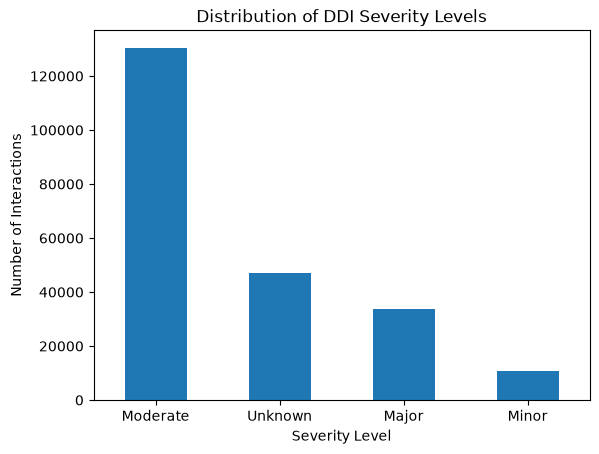

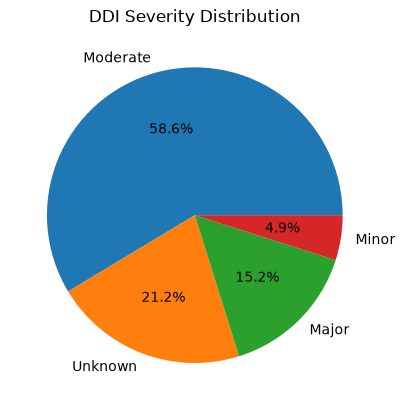

In [8]:
import matplotlib.pyplot as plt

df["Level"].value_counts().plot(kind="bar")

plt.title("Distribution of DDI Severity Levels")
plt.xlabel("Severity Level")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=0)
plt.show()



df["Level"].value_counts().plot(kind="pie", autopct="%1.1f%%")

plt.title("DDI Severity Distribution")
plt.ylabel("")
plt.show()

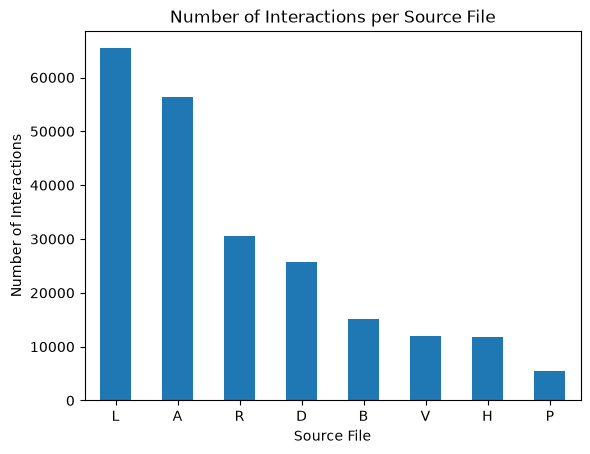

In [9]:
df["Source_File"].value_counts().plot(kind="bar")

plt.title("Number of Interactions per Source File")
plt.xlabel("Source File")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=0)
plt.show()

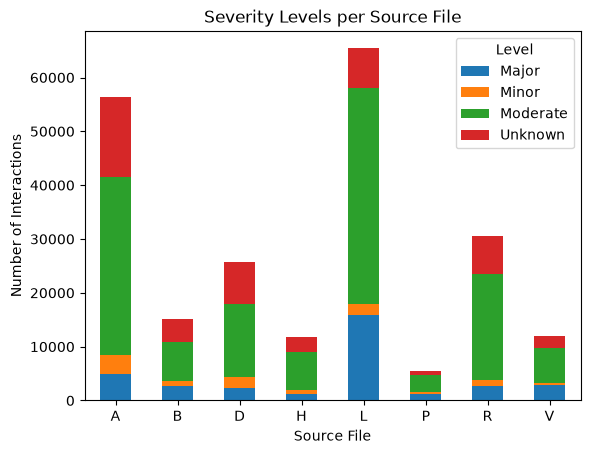

In [10]:
pd.crosstab(df["Source_File"], df["Level"]).plot(
    kind="bar",
    stacked=True
)

plt.title("Severity Levels per Source File")
plt.xlabel("Source File")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=0)
plt.show()

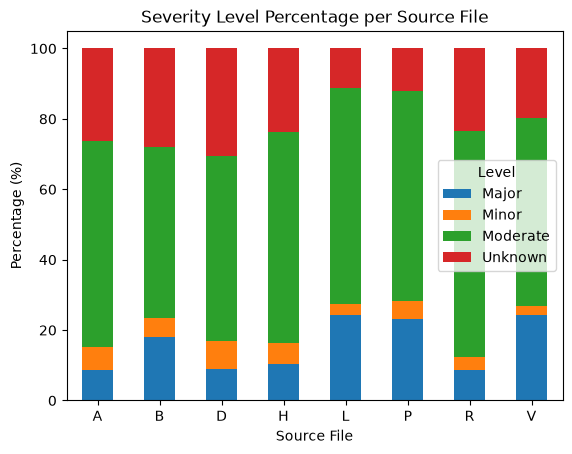

In [11]:
severity_percentage = pd.crosstab(
    df["Source_File"],
    df["Level"],
    normalize="index"
) * 100

severity_percentage.plot(
    kind="bar",
    stacked=True
)

plt.title("Severity Level Percentage per Source File")
plt.xlabel("Source File")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Level")
plt.show()